# Advanced LLM Fine Tuning · Train embeddings and rerankers

A search system can miss because the right document never reaches the shortlist, or because the ranker
puts it too low. On BEIR SciFact, build both stages and measure them independently.

- Compare lexical retrieval with pretrained and fine-tuned MiniLM embeddings.
- Change only how training negatives are selected. Compare random negatives with lexical hard negatives.
- Send one frozen candidate list to an unadapted and a fine-tuned MiniLM reranker.

The notebook uses one Colab GPU and downloads public weights and benchmark files. It makes no calls
to a hosted inference API. Keep the official test queries closed until the configurations are set.

## 1. Record the environment

The CUDA check makes the runtime boundary explicit. Package versions and weight revisions identify the run.
The model files are public safetensors. The notebook has no account tokens or private datasets.

In [1]:
import subprocess, sys
subprocess.run([
    sys.executable, "-m", "pip", "install", "--quiet",
    "transformers==4.51.3", "sentence-transformers==4.1.0", "rank-bm25==0.2.2",
], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '--quiet', 'transformers==4.51.3', 'sentence-transformers==4.1.0', 'rank-bm25==0.2.2'], returncode=0)

In [2]:
import hashlib
import json
import platform
import re
from collections import defaultdict
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer
from transformers import AutoModelForSequenceClassification, AutoTokenizer, set_seed

SEED = 42
EPOCHS = 2
BATCH = 24
PAIR_BATCH = 64
MAX_LENGTH = 192
CANDIDATES = 20
EMBEDDING = "sentence-transformers/all-MiniLM-L6-v2"
EMBEDDING_REV = "1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
RERANKER = "cross-encoder/ms-marco-MiniLM-L6-v2"
RERANKER_REV = "233902d25c440f23af6f7d6e94d2946bac0bee0a"
CORPUS_REV = "b3b5335604bf5ee3c4447671af975ea25143d4f5"
QRELS_REV = "2938d17dc3b09882fdb8c12bbbe2e2dc0e75a029"
RATE = 2e-5
assert torch.cuda.is_available(), "Select a GPU in Colab: Runtime > Change runtime type."
set_seed(SEED)
DEVICE = "cuda"
START = perf_counter()
GPU = torch.cuda.get_device_properties(0)
print(f"{GPU.name} | {GPU.total_memory / 2**30:.2f} GiB | CUDA {torch.version.cuda}")
print(f"Python {platform.python_version()}")
for package in ("torch", "transformers", "sentence-transformers", "rank-bm25", "pyarrow", "pandas", "numpy"):
    print(f"{package} {version(package)}")

def enforce_runtime_budget():
    if perf_counter() - START > 25 * 60:
        raise TimeoutError("Stopped at the 25-minute run budget. Check runtime and GPU before retrying.")

Tesla T4 | 14.56 GiB | CUDA 13.0
Python 3.13.16
torch 2.14.1+cu130
transformers 4.51.3
sentence-transformers 4.1.0
rank-bm25 0.2.2
pyarrow 23.0.1
pandas 2.2.3
numpy 2.4.6


## 2. What counts as relevant?

SciFact contains claims, abstracts and relevance judgments. This experiment retrieves a labelled
abstract for a given claim. It scores retrieval even when an abstract disputes the claim.

Keep the official test queries and remove training queries whose normalised text matches any test query. Use one searchable corpus. A document can appear in both splits.
This measures generalisation to held-out queries. Check and report document overlap before training.

In [3]:
def read_items(split):
    path = hf_hub_download(
        "BeIR/scifact", f"{split}/{split}-00000-of-00001.parquet",
        repo_type="dataset", revision=CORPUS_REV,
    )
    frame = pd.read_parquet(path).fillna("")
    if split == "corpus":
        return {str(r["_id"]): f"{r['title']} {r['text']}".strip() for r in frame.to_dict("records")}
    return dict(zip(frame["_id"].astype(str), frame["text"]))

def read_judgments(split):
    path = hf_hub_download(
        "BeIR/scifact-qrels", f"{split}.tsv", repo_type="dataset", revision=QRELS_REV,
    )
    frame = pd.read_csv(path, sep="\t", dtype={"query-id": str, "corpus-id": str})
    judgments = defaultdict(dict)
    for query, document, grade in frame.itertuples(index=False, name=None):
        if grade > 0:
            judgments[query][document] = int(grade)
    return dict(judgments)

documents = read_items("corpus")
queries = read_items("queries")
train_labels = read_judgments("train")
test_labels = read_judgments("test")
train_ids, test_ids, doc_ids = map(sorted, (train_labels, test_labels, documents))
assert set(train_ids).isdisjoint(test_ids)
normalize = lambda text: " ".join(re.findall(r"\w+", text.casefold()))
test_text = {normalize(queries[q]) for q in test_ids}
duplicate_ids = [q for q in train_ids if normalize(queries[q]) in test_text]
for q in duplicate_ids:
    del train_labels[q]
train_ids = sorted(train_labels)
assert {normalize(queries[q]) for q in train_ids}.isdisjoint(test_text)
print(f"Excluded {len(duplicate_ids)} training queries duplicated by text in the official test set.")
train_documents = set().union(*train_labels.values())
test_documents = set().union(*test_labels.values())
assert train_documents | test_documents <= documents.keys()
print(f"{len(doc_ids):,} indexed documents; {len(train_ids):,} train and {len(test_ids):,} test queries.")
print(f"{len(train_documents & test_documents):,} relevant documents occur in both query splits.")
split_sha = hashlib.sha256(json.dumps([train_ids, test_ids], separators=(",", ":")).encode()).hexdigest()
print("Query-split SHA-256:", split_sha)

Excluded 2 training queries duplicated by text in the official test set.
5,183 indexed documents; 807 train and 300 test queries.
181 relevant documents occur in both query splits.
Query-split SHA-256: 89a69035fc17f7144051bcab34b41aaf8647cce8e0d114abfb9c1783476f4fbb


## 3. Control which negatives the model sees

A random abstract often shares little with the query. A high-ranking BM25 abstract can share the right
keywords while answering the wrong question. For each training query, fix one labelled positive and
supply one example of either type. Screen out every known positive for that query.

The remaining hard negatives are **unjudged**. They can include relevant papers missing from the labels.
This is a limitation to inspect alongside the training result.

In [4]:
def tokenize_words(text):
    return re.findall(r"\w+", text.casefold())

bm25 = BM25Okapi([tokenize_words(documents[doc]) for doc in doc_ids])

def lexical_rank(query_id):
    scores = bm25.get_scores(tokenize_words(queries[query_id]))
    return [doc_ids[i] for i in np.argsort(-scores, kind="stable")]

rng = np.random.default_rng(SEED)
random_rows, hard_rows = [], []
for qid in train_ids:
    relevant = train_labels[qid]
    positive = min(relevant, key=lambda doc: (-relevant[doc], doc))
    pool = lexical_rank(qid)[:50]
    hard = next(doc for doc in pool if doc not in relevant)
    random_negative = rng.choice(doc_ids)
    while random_negative in relevant or random_negative in pool:
        random_negative = rng.choice(doc_ids)
    assert hard not in relevant and random_negative not in relevant
    random_rows.append((qid, positive, str(random_negative)))
    hard_rows.append((qid, positive, hard))
assert [row[:2] for row in random_rows] == [row[:2] for row in hard_rows]
print(f"{len(hard_rows):,} matched training triplets per branch")
for kind, rows in [("Random", random_rows), ("Hard", hard_rows)]:
    overlap = []
    for qid, _, negative in rows:
        terms = set(tokenize_words(queries[qid]))
        overlap.append(len(terms.intersection(tokenize_words(documents[negative]))) / max(1, len(terms)))
    print(f"{kind:6} median query-term coverage in negative: {np.median(overlap):.1%}")

807 matched training triplets per branch
Random median query-term coverage in negative: 22.7%
Hard   median query-term coverage in negative: 57.1%


## 4. Train two embedding branches

Use the same pretrained weights, seed, batches, positives, length limit, optimiser and step count.
Each query chooses between the positive and negative document using cosine similarity. The loss
penalises ranking the negative above the positive. The two models can see different numbers of
non-padding tokens because their negative documents differ.

In [5]:
def new_encoder():
    return SentenceTransformer(
        EMBEDDING, revision=EMBEDDING_REV, device=DEVICE, trust_remote_code=False,
        model_kwargs={"use_safetensors": True},
    )

def batches(rows):
    for epoch in range(EPOCHS):
        order = np.random.default_rng(SEED + epoch).permutation(len(rows))
        for start in range(0, len(order), BATCH):
            enforce_runtime_budget()
            yield [rows[i] for i in order[start:start+BATCH]]

def fit_encoder(rows):
    set_seed(SEED)
    model = new_encoder()
    model.max_seq_length = MAX_LENGTH
    model.train()
    optimiser = torch.optim.AdamW(model.parameters(), lr=RATE)
    history = []
    for batch in batches(rows):
        texts = [
            *(queries[q] for q, _, _ in batch),
            *(documents[p] for _, p, _ in batch),
            *(documents[n] for _, _, n in batch),
        ]
        tokens = {key: value.to(DEVICE) for key, value in model.tokenize(texts).items()}
        vectors = F.normalize(model(tokens)["sentence_embedding"], dim=1)
        query, positive, negative = vectors.chunk(3)
        logits = torch.stack(((query * positive).sum(1), (query * negative).sum(1)), dim=1) / 0.05
        loss = F.cross_entropy(logits, torch.zeros(len(batch), device=DEVICE, dtype=torch.long))
        optimiser.zero_grad(set_to_none=True)
        loss.backward()
        optimiser.step()
        history.append(loss.item())
    assert np.isfinite(history).all()
    return model.eval(), history

def train_and_log(label, fit, rows):
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    start = perf_counter()
    model, history = fit(rows)
    torch.cuda.synchronize()
    info = {
        "steps": len(history),
        "seconds": perf_counter() - start,
        "peak_allocated_gib": torch.cuda.max_memory_allocated() / 2**30,
        "mean_last_10_loss": float(np.mean(history[-10:])),
    }
    print(label, json.dumps(info))
    return model, info

random_encoder, random_run = train_and_log("Random negatives", fit_encoder, random_rows)
hard_encoder, hard_run = train_and_log("Hard negatives", fit_encoder, hard_rows)
assert random_run["steps"] == hard_run["steps"]

Random negatives {"steps": 68, "seconds": 38.41087689, "peak_allocated_gib": 2.428598403930664, "mean_last_10_loss": 0.0024244930304121227}
Hard negatives {"steps": 68, "seconds": 28.663941411999986, "peak_allocated_gib": 2.5982131958007812, "mean_last_10_loss": 0.24422103464603423}


## 5. Fine-tune the reranker

The cross-encoder reads the claim and abstract together. It scores richer interactions at the cost
of one forward pass for each pair. Train it on the hard-negative pairs, then give the original and
adapted rerankers the same top-20 list from the hard-negative embedding branch. Neither model can
promote a document outside that list.

In [6]:
pair_tokenizer = AutoTokenizer.from_pretrained(RERANKER, revision=RERANKER_REV, trust_remote_code=False)

def new_reranker():
    return AutoModelForSequenceClassification.from_pretrained(
        RERANKER, revision=RERANKER_REV, use_safetensors=True, trust_remote_code=False,
    ).to(DEVICE)

def pair_scores(model, query_ids, document_ids):
    tokens = pair_tokenizer(
        [queries[q] for q in query_ids], [documents[d] for d in document_ids],
        padding=True, truncation=True, max_length=MAX_LENGTH, return_tensors="pt",
    ).to(DEVICE)
    return model(**tokens).logits.reshape(-1)

def fit_reranker(rows):
    set_seed(SEED)
    model = new_reranker().train()
    optimiser = torch.optim.AdamW(model.parameters(), lr=RATE)
    history = []
    for batch in batches(rows):
        qids = [q for q, _, _ in batch]
        ids = [p for _, p, _ in batch] + [n for _, _, n in batch]
        positive, negative = pair_scores(model, qids + qids, ids).chunk(2)
        loss = F.softplus(negative - positive).mean()
        optimiser.zero_grad(set_to_none=True)
        loss.backward()
        optimiser.step()
        history.append(loss.item())
    assert np.isfinite(history).all()
    return model.eval(), history

tuned_reranker, ranker_run = train_and_log("Adapted reranker", fit_reranker, hard_rows)

Adapted reranker {"steps": 68, "seconds": 23.870179120000046, "peak_allocated_gib": 2.0660037994384766, "mean_last_10_loss": 0.4951109677553177}


## 6. Read retrieval and ranking as different outcomes

Recall@20 measures how many judged relevant abstracts make the shortlist. nDCG@10 rewards bringing
graded relevance near the top. Use all labelled test queries, including those with no relevant
document in the shortlist. A fixed-candidate rerank must leave Recall@20 unchanged.

In [7]:
def dense_rank(model):
    enforce_runtime_budget()
    model.max_seq_length = MAX_LENGTH
    doc_vectors = model.encode(
        [documents[d] for d in doc_ids], batch_size=PAIR_BATCH,
        normalize_embeddings=True, convert_to_tensor=True, show_progress_bar=False,
    )
    query_vectors = model.encode(
        [queries[q] for q in test_ids], batch_size=PAIR_BATCH,
        normalize_embeddings=True, convert_to_tensor=True, show_progress_bar=False,
    )
    scores = (query_vectors @ doc_vectors.T).cpu().numpy()
    indices = np.argsort(-scores, axis=1, kind="stable")[:, :CANDIDATES]
    return {q: [doc_ids[i] for i in row] for q, row in zip(test_ids, indices)}

@torch.inference_mode()
def rerank(model, candidates):
    flattened = [(q, doc) for q in test_ids for doc in candidates[q]]
    scores = []
    for start in range(0, len(flattened), PAIR_BATCH):
        enforce_runtime_budget()
        segment = flattened[start:start + PAIR_BATCH]
        scores.extend(pair_scores(model, *zip(*segment)).cpu().tolist())
    scores = np.asarray(scores).reshape(len(test_ids), CANDIDATES)
    return {
        q: [candidates[q][i] for i in np.argsort(-row, kind="stable")]
        for q, row in zip(test_ids, scores)
    }

runs = {
    "Lexical BM25": {q: lexical_rank(q)[:CANDIDATES] for q in test_ids},
    "Frozen embedding": dense_rank(new_encoder()),
    "Random negatives": dense_rank(random_encoder),
    "Hard negatives": dense_rank(hard_encoder),
}
frozen_candidates = runs["Hard negatives"]
runs["Frozen reranker"] = rerank(new_reranker().eval(), frozen_candidates)
runs["Tuned reranker"] = rerank(tuned_reranker, frozen_candidates)
for label in ("Frozen reranker", "Tuned reranker"):
    assert all(set(runs[label][q]) == set(frozen_candidates[q]) for q in test_ids)

In [8]:
def metrics(ranking, relevant):
    retrieved = sum(doc in relevant for doc in ranking[:20]) / len(relevant)
    discounts = np.log2(np.arange(2, 12))
    grades = np.array([relevant.get(doc, 0) for doc in ranking[:10]])
    dcg = ((2**grades - 1) / discounts[:len(grades)]).sum()
    ideal = np.array(sorted(relevant.values(), reverse=True)[:10])
    idcg = ((2**ideal - 1) / discounts[:len(ideal)]).sum()
    return retrieved, dcg / idcg

def bootstrap_delta(changed, baseline):
    difference = np.asarray(changed) - np.asarray(baseline)
    sample = np.random.default_rng(SEED).integers(0, len(difference), size=(3000, len(difference)))
    low, high = np.quantile(difference[sample].mean(axis=1), [0.025, 0.975])
    return difference.mean(), low, high

by_query = pd.DataFrame([
    {"method": label, "query_id": q, "Recall@20": recall, "nDCG@10": ndcg}
    for label, ranking in runs.items() for q in test_ids
    for recall, ndcg in [metrics(ranking[q], test_labels[q])]
])
summary = by_query.groupby("method", sort=False)[["Recall@20", "nDCG@10"]].mean()
assert summary.loc[["Hard negatives", "Frozen reranker", "Tuned reranker"], "Recall@20"].nunique() == 1
print(summary.round(4).to_string())
paired = by_query.pivot(index="query_id", columns="method", values="nDCG@10")
for changed, baseline in [("Hard negatives", "Random negatives"), ("Tuned reranker", "Frozen reranker")]:
    delta, low, high = bootstrap_delta(paired[changed], paired[baseline])
    print(f"{changed} vs {baseline}: {delta:+.4f} nDCG, paired query bootstrap [{low:+.4f}, {high:+.4f}]")

                  Recall@20  nDCG@10
method                              
Lexical BM25         0.8323   0.6519
Frozen embedding     0.8333   0.6443
Random negatives     0.8567   0.6553
Hard negatives       0.8341   0.6552
Frozen reranker      0.8341   0.6828
Tuned reranker       0.8341   0.6133
Hard negatives vs Random negatives: -0.0001 nDCG, paired query bootstrap [-0.0292, +0.0307]
Tuned reranker vs Frozen reranker: -0.0696 nDCG, paired query bootstrap [-0.0948, -0.0442]


## 7. Find a failure the reranker cannot fix

Measure reranker latency on a small, fixed single-query workload, with the same pairs and a warm-up
for each model. This is notebook latency, including tokenisation and data transfer. Then inspect
where the candidate generator left no known relevant document for either reranker.

In [9]:
@torch.inference_mode()
def rank_latency(model, workload):
    for qid in workload[:5]:
        pair_scores(model, [qid] * CANDIDATES, frozen_candidates[qid])
    torch.cuda.synchronize()
    samples = []
    for qid in workload:
        enforce_runtime_budget()
        start = perf_counter()
        pair_scores(model, [qid] * CANDIDATES, frozen_candidates[qid])
        torch.cuda.synchronize()
        samples.append(1000 * (perf_counter() - start))
    return {"p50_ms": float(np.median(samples)), "p95_ms": float(np.percentile(samples, 95))}

workload = test_ids[:60]
latency = {
    "Frozen reranker": rank_latency(new_reranker().eval(), workload),
    "Tuned reranker": rank_latency(tuned_reranker, workload),
}
print(f"Reranker latency over {len(workload)} queries, {CANDIDATES} pairs per query")
print(pd.DataFrame(latency).T.round(2).to_string())
missing = [q for q in test_ids if set(frozen_candidates[q]).isdisjoint(test_labels[q])]
print(f"Queries with zero shortlist recall: {len(missing)}/{len(test_ids)}.")
if missing:
    example = missing[0]
    print("Example query ID:", example)
    print("Judged relevant document IDs:", sorted(test_labels[example]))
    print("Shortlist top five:", frozen_candidates[example][:5])

Reranker latency over 60 queries, 20 pairs per query
                 p50_ms  p95_ms
Frozen reranker   44.58   51.01
Tuned reranker    44.58   52.05
Queries with zero shortlist recall: 46/300.
Example query ID: 100
Judged relevant document IDs: ['4381486']
Shortlist top five: ['9154703', '13980338', '2608447', '8290760', '10766688']


## 8. Save the result

Read the left and right panels together. If recall stays flat but nDCG rises, the shortlist stayed
fixed while ordering improved. The paired interval quantifies test-query uncertainty for the evaluation.
It does not cover training-seed variability or label incompleteness.

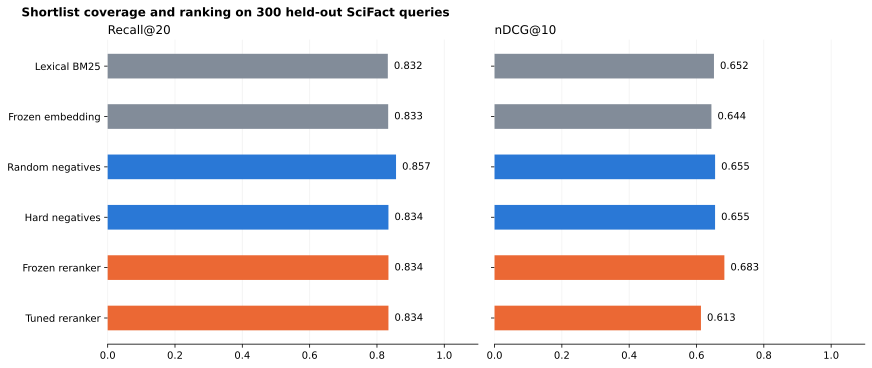

Saved scifact_run.json and scifact_query_metrics.csv in the runtime.
{"batch": 24, "cuda": "13.0", "data_revisions": {"BeIR/scifact": "b3b5335604bf5ee3c4447671af975ea25143d4f5", "BeIR/scifact-qrels": "2938d17dc3b09882fdb8c12bbbe2e2dc0e75a029"}, "elapsed_seconds": 198.443742972, "epochs": 2, "gpu": "Tesla T4", "indexed_documents": 5183, "latency": {"Frozen reranker": {"p50_ms": 44.57649549999587, "p95_ms": 51.012107800019635}, "Tuned reranker": {"p50_ms": 44.582086500014384, "p95_ms": 52.04513509998491}}, "learning_rate": 2e-05, "length_limit": 192, "metrics": {"Frozen embedding": {"Recall@20": 0.8333333333333334, "nDCG@10": 0.6443494039456269}, "Frozen reranker": {"Recall@20": 0.834111111111111, "nDCG@10": 0.6828309261722674}, "Hard negatives": {"Recall@20": 0.834111111111111, "nDCG@10": 0.6551681647409662}, "Lexical BM25": {"Recall@20": 0.8322777777777778, "nDCG@10": 0.6518925893260478}, "Random negatives": {"Recall@20": 0.8566666666666667, "nDCG@10": 0.6552619421699692}, "Tuned reran

In [10]:
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")

figure, axes = plt.subplots(1, 2, figsize=(12, 5), layout="constrained", sharey=True)
colours = ["#828c99"] * 2 + ["#2a78d6", "#2a78d6", "#eb6834", "#eb6834"]
positions = np.arange(len(summary))
for ax, metric in zip(axes, ("Recall@20", "nDCG@10")):
    values = summary[metric].to_numpy()
    ax.barh(positions, values, color=colours, height=0.49)
    ax.set_xlim(0, 1.10)
    ax.set_title(metric, loc="left")
    ax.set_yticks(positions, summary.index)
    ax.grid(axis="x", alpha=.17)
    ax.set_axisbelow(True)
    ax.spines[["top", "right", "left"]].set_visible(False)
    for position, value in zip(positions, values):
        ax.text(value + .018, position, f"{value:.3f}", va="center", fontsize=10)
axes[0].invert_yaxis()
figure.suptitle(f"Shortlist coverage and ranking on {len(test_ids)} held-out SciFact queries",
                x=.02, ha="left", fontweight="bold")
plt.show()

report = {
    "gpu": GPU.name,
    "cuda": torch.version.cuda,
    "python": platform.python_version(),
    "packages": {p: version(p) for p in ("torch", "transformers", "sentence-transformers", "rank-bm25", "pyarrow", "pandas", "numpy")},
    "seed": SEED,
    "epochs": EPOCHS,
    "batch": BATCH,
    "length_limit": MAX_LENGTH,
    "learning_rate": RATE,
    "query_split_sha256": split_sha,
    "indexed_documents": len(doc_ids),
    "train_queries": len(train_ids),
    "test_queries": len(test_ids),
    "model_revisions": {EMBEDDING: EMBEDDING_REV, RERANKER: RERANKER_REV},
    "data_revisions": {"BeIR/scifact": CORPUS_REV, "BeIR/scifact-qrels": QRELS_REV},
    "training": {"random_negatives": random_run, "hard_negatives": hard_run, "reranker": ranker_run},
    "metrics": summary.to_dict(orient="index"),
    "latency": latency,
    "elapsed_seconds": perf_counter() - START,
}
Path("scifact_run.json").write_text(json.dumps(report, indent=2))
by_query.to_csv("scifact_query_metrics.csv", index=False)
print("Saved scifact_run.json and scifact_query_metrics.csv in the runtime.")
print(json.dumps(report, sort_keys=True))

## Sources

- [BEIR SciFact](https://huggingface.co/datasets/BeIR/scifact) and [relevance judgments](https://huggingface.co/datasets/BeIR/scifact-qrels), Hugging Face mirror labelled CC BY-SA 4.0. [Original SciFact paper and corpus](https://aclanthology.org/2020.emnlp-main.609/).
- [MiniLM sentence embeddings](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2) and [MS MARCO MiniLM cross-encoder](https://huggingface.co/cross-encoder/ms-marco-MiniLM-L6-v2), model cards labelled Apache-2.0.
- [NVIDIA’s domain-specific embedding recipe](https://huggingface.co/blog/nvidia/domain-specific-embedding-finetune), for a separate published workflow.